In [14]:
import os
import ast
import json
import copy
import random
import warnings
import re

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

import joblib

warnings.filterwarnings("ignore")

In [15]:

PROJECT_ROOT = Path(
    r"C:\Users\lokan\Document\DL\ENDSEM"
)

SPLIT_ROOT = PROJECT_ROOT / "data" / "split files"

SPLIT_FILE = PROJECT_ROOT / "I3_cell_split.csv"

TARGET_FILE = PROJECT_ROOT / "I3_cycle_life_targets.csv"

IMAGE_ROOT = PROJECT_ROOT / "images_2d"

RESULT_ROOT = PROJECT_ROOT / "results"

PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"

HORIZONS = [10, 30, 100]

SPLITS = ["train", "val", "test"]

EXPECTED_COUNTS = {
    "train": 75,
    "val": 24,
    "test": 29
}

VOLTAGE_LENGTH = 1000

SUMMARY_FEATURES = [
    "capacity",
    "duration",
    "temperature_mean",
    "temperature_max",
    "current_mean",
    "voltage_mean"
]

SEED = 22

for folder in [
    IMAGE_ROOT,
    RESULT_ROOT,
    PROCESSED_ROOT
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Configuration completed.")

Configuration completed.


In [16]:
import pandas as pd
import numpy as np

cell_split = pd.read_csv(SPLIT_FILE)

targets = pd.read_csv(TARGET_FILE)

print("Cell split:", cell_split.shape)
print("Targets:", targets.shape)

print("\nCell split columns:")
print(cell_split.columns.tolist())

print("\nTarget columns:")
print(targets.columns.tolist())

display(cell_split.head())
display(targets.head())

Cell split: (128, 5)
Targets: (128, 5)

Cell split columns:
['cell', 'start_batch', 'records', 'cycles_listed', 'part']

Target columns:
['cell', 'start_batch', 'part', 'cycle_life_target', 'rule']


,cell,start_batch,records,cycles_listed,part
0,el150800460514,2017-05-12,17-05ch1+17-06ch1,1855,test
1,el150800460601,2017-05-12,17-05ch38,649,test
2,el150800460622,2017-05-12,17-05ch40,704,test
3,el150800460640,2017-05-12,17-05ch29,732,test
4,el150800460659,2017-05-12,17-05ch33,871,test


,cell,start_batch,part,cycle_life_target,rule
0,el150800440551,2017-06-30,train,461,A
1,el150800453113,2017-05-12,val,719,A
2,el150800453240,2017-05-12,train,691,A
3,el150800453773,2017-05-12,train,617,A
4,el150800460436,2017-05-12,train,757,A


In [17]:
def normalize_id(value):

    if pd.isna(value):
        return ""

    return str(value).strip().lower()


def normalize_date(value):

    return pd.to_datetime(value).strftime("%Y-%m-%d")


cell_split["cell"] = cell_split["cell"].apply(normalize_id)

targets["cell"] = targets["cell"].apply(normalize_id)

cell_split["start_batch"] = cell_split["start_batch"].apply(
    normalize_date
)

targets["start_batch"] = targets["start_batch"].apply(
    normalize_date
)

cell_split["part"] = cell_split["part"].str.lower().str.strip()

targets["part"] = targets["part"].str.lower().str.strip()

targets["cycle_life_target"] = pd.to_numeric(
    targets["cycle_life_target"],
    errors="raise"
)

assert len(cell_split) == 128

assert len(targets) == 128

assert not cell_split.duplicated(
    ["cell", "start_batch"]
).any()

assert not targets.duplicated(
    ["cell", "start_batch"]
).any()

print("Split counts:")
print(cell_split["part"].value_counts())

print("\nTarget counts:")
print(targets["part"].value_counts())

assert cell_split["part"].value_counts().to_dict() == {
    "train": 75,
    "test": 29,
    "val": 24
}

print("\nOfficial split verified.")

Split counts:
part
train    75
test     29
val      24
Name: count, dtype: int64

Target counts:
part
train    75
test     29
val      24
Name: count, dtype: int64

Official split verified.


In [18]:
merged_check = cell_split.merge(
    targets,
    on=["cell", "start_batch"],
    how="outer",
    suffixes=("_split", "_target"),
    indicator=True
)

print(merged_check["_merge"].value_counts())

assert (merged_check["_merge"] == "both").all()

assert (
    merged_check["part_split"] ==
    merged_check["part_target"]
).all()

print("All 128 targets and partitions match.")

# Official target mapping
target_table = targets.set_index(
    ["cell", "start_batch"]
)

# Barcode lookup
assert cell_split["cell"].is_unique

cell_lookup = (
    cell_split
    .set_index("cell")
    .to_dict("index")
)

target_lookup = {
    (row["cell"], row["start_batch"]):
        float(row["cycle_life_target"])
    for _, row in targets.iterrows()
}

print("Target mapping created.")

_merge
both          128
left_only       0
right_only      0
Name: count, dtype: int64
All 128 targets and partitions match.
Target mapping created.


In [19]:
def get_csv_path(horizon, split):

    folder = (
        SPLIT_ROOT /
        f"{horizon}_cycles_split"
    )

    path = folder / f"cycles_{horizon}_{split}.csv"

    if not path.exists():
        raise FileNotFoundError(
            f"Missing feature file: {path}"
        )

    return path


FEATURE_FILES = {}

for horizon in HORIZONS:

    FEATURE_FILES[horizon] = {}

    for split in SPLITS:

        path = get_csv_path(horizon, split)

        df = pd.read_csv(path)

        FEATURE_FILES[horizon][split] = df

        print(
            f"{horizon} cycles | {split} | "
            f"Shape: {df.shape}"
        )

        print("Columns:", df.columns.tolist()[:20])

10 cycles | train | Shape: (750, 19)
Columns: ['cell_idx', 'batch_date', 'policy', 'policy_readable', 'barcode', 'channel_id', 'cycle_life', 'cycle_index', 'discharge_dQdV', 't', 'Qc', 'I', 'V', 'T', 'Qd', 'Qdlin', 'Tdlin', 'summary', 'Vdlin']
10 cycles | val | Shape: (240, 19)
Columns: ['cell_idx', 'batch_date', 'policy', 'policy_readable', 'barcode', 'channel_id', 'cycle_life', 'cycle_index', 'discharge_dQdV', 't', 'Qc', 'I', 'V', 'T', 'Qd', 'Qdlin', 'Tdlin', 'summary', 'Vdlin']
10 cycles | test | Shape: (290, 19)
Columns: ['cell_idx', 'batch_date', 'policy', 'policy_readable', 'barcode', 'channel_id', 'cycle_life', 'cycle_index', 'discharge_dQdV', 't', 'Qc', 'I', 'V', 'T', 'Qd', 'Qdlin', 'Tdlin', 'summary', 'Vdlin']
30 cycles | train | Shape: (2250, 19)
Columns: ['cell_idx', 'batch_date', 'policy', 'policy_readable', 'barcode', 'channel_id', 'cycle_life', 'cycle_index', 'discharge_dQdV', 't', 'Qc', 'I', 'V', 'T', 'Qd', 'Qdlin', 'Tdlin', 'summary', 'Vdlin']
30 cycles | val | Shape: (

In [20]:
def verify_feature_files():

    for horizon in HORIZONS:

        for split in SPLITS:

            df = FEATURE_FILES[horizon][split]

            assert "barcode" in df.columns, (
                f"barcode missing in {horizon}/{split}"
            )

            df["barcode"] = df["barcode"].apply(
                normalize_id
            )

            expected = set(
                cell_split.loc[
                    cell_split["part"] == split,
                    "cell"
                ]
            )

            observed = set(df["barcode"].unique())

            missing = expected - observed
            unexpected = observed - expected

            print(
                f"\n{horizon} cycles | {split}"
            )

            print("Expected cells:", len(expected))
            print("Observed cells:", len(observed))

            if missing:
                print("Missing cells:", sorted(missing))

            if unexpected:
                print("Unexpected cells:", sorted(unexpected))

            assert not missing, (
                f"Missing cells in {horizon}/{split}"
            )

            assert not unexpected, (
                f"Unexpected cells in {horizon}/{split}"
            )


verify_feature_files()


10 cycles | train
Expected cells: 75
Observed cells: 75

10 cycles | val
Expected cells: 24
Observed cells: 24

10 cycles | test
Expected cells: 29
Observed cells: 29

30 cycles | train
Expected cells: 75
Observed cells: 75

30 cycles | val
Expected cells: 24
Observed cells: 24

30 cycles | test
Expected cells: 29
Observed cells: 29

100 cycles | train
Expected cells: 75
Observed cells: 75

100 cycles | val
Expected cells: 24
Observed cells: 24

100 cycles | test
Expected cells: 29
Observed cells: 29


In [21]:
import ast
import json
import re


def parse_array(value):

    if value is None:
        return np.array([], dtype=np.float32)

    if isinstance(value, np.ndarray):
        return np.asarray(
            value,
            dtype=np.float32
        ).flatten()

    if isinstance(value, (list, tuple)):
        return np.asarray(
            value,
            dtype=np.float32
        ).flatten()

    if isinstance(value, (int, float, np.number)):

        if pd.isna(value):
            return np.array([], dtype=np.float32)

        return np.array([value], dtype=np.float32)

    text = str(value).strip()

    if not text or text.lower() in ["nan", "none", "null"]:
        return np.array([], dtype=np.float32)

    for parser in [ast.literal_eval, json.loads]:

        try:

            parsed = parser(text)

            return np.asarray(
                parsed,
                dtype=np.float32
            ).flatten()

        except Exception:
            continue

    numbers = re.findall(
        r"[-+]?(?:\d*\.)?\d+(?:[eE][-+]?\d+)?",
        text
    )

    return np.asarray(
        numbers,
        dtype=np.float32
    )

In [22]:
def normalize_vector(values, length=VOLTAGE_LENGTH):

    values = np.asarray(
        values,
        dtype=np.float32
    ).flatten()

    if len(values) == 0:
        raise ValueError("Empty Qdlin array.")

    valid = np.isfinite(values)

    if not valid.any():
        raise ValueError("Qdlin contains no finite values.")

    # Interpolate missing values
    positions = np.arange(len(values))

    values = np.interp(
        positions,
        positions[valid],
        values[valid]
    )

    # Resample only if the length differs
    if len(values) != length:

        old_positions = np.linspace(
            0, 1, len(values)
        )

        new_positions = np.linspace(
            0, 1, length
        )

        values = np.interp(
            new_positions,
            old_positions,
            values
        )

    return values.astype(np.float32)


def get_qdlin(row):

    # First try the array column
    if "Qdlin" in row.index:

        values = parse_array(row["Qdlin"])

        if len(values) > 0:

            return normalize_vector(values)

    # Otherwise use wide-format columns
    columns = [
        c for c in row.index
        if re.fullmatch(r"Qdlin_\d+", str(c))
    ]

    if columns:

        columns = sorted(
            columns,
            key=lambda x: int(x.split("_")[-1])
        )

        values = pd.to_numeric(
            row[columns],
            errors="coerce"
        ).to_numpy(dtype=np.float32)

        return normalize_vector(values)

    raise ValueError(
        "Neither Qdlin nor Qdlin_1...Qdlin_1000 found."
    )

In [23]:
def get_array(row, column):

    if column not in row.index:
        return np.array([], dtype=np.float32)

    return parse_array(row[column])


def safe_mean(values):

    values = np.asarray(values, dtype=float)

    values = values[np.isfinite(values)]

    return float(np.mean(values)) if len(values) else np.nan


def safe_max(values):

    values = np.asarray(values, dtype=float)

    values = values[np.isfinite(values)]

    return float(np.max(values)) if len(values) else np.nan


def get_duration(values):

    values = np.asarray(values, dtype=float)

    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan

    return float(np.max(values) - np.min(values))


def get_last_valid(values):

    values = np.asarray(values, dtype=float)

    values = values[np.isfinite(values)]

    return float(values[-1]) if len(values) else np.nan


def extract_cycle_summary(row):

    Qd = get_array(row, "Qd")
    t = get_array(row, "t")
    T = get_array(row, "T")
    I = get_array(row, "I")
    V = get_array(row, "V")

    return np.array([

        get_last_valid(Qd),

        get_duration(t),

        safe_mean(T),

        safe_max(T),

        safe_mean(I),

        safe_mean(V)

    ], dtype=np.float32)

In [24]:
def get_cycle_index_column(df):

    for col in ["cycle_index", "cycle"]:

        if col in df.columns:
            return col

    raise ValueError(
        "Neither cycle_index nor cycle column exists."
    )


def get_endpoint_row(group, cycle_number, cycle_col):

    matched = group[
        group[cycle_col] == cycle_number
    ]

    if len(matched) != 1:

        raise ValueError(
            f"Expected exactly one row for cycle "
            f"{cycle_number}, found {len(matched)}"
        )

    return matched.iloc[0]


def build_cell_dataset(horizon, split):

    df = FEATURE_FILES[horizon][split].copy()

    cycle_col = get_cycle_index_column(df)

    df[cycle_col] = pd.to_numeric(
        df[cycle_col],
        errors="coerce"
    )

    df = df.dropna(subset=[cycle_col])

    df[cycle_col] = df[cycle_col].astype(int)

    delta_list = []
    summary_list = []
    image_list = []
    labels = []
    cell_ids = []

    # Endpoints specified by the project protocol
    endpoints = {
        10: (2, 10),
        30: (2, 30),
        100: (10, 100)
    }

    first_cycle, last_cycle = endpoints[horizon]

    # Each barcode represents one physical cell
    for barcode, group in df.groupby(
        "barcode",
        sort=False
    ):

        barcode = normalize_id(barcode)

        if barcode not in cell_lookup:

            raise ValueError(
                f"Barcode not found in official split: {barcode}"
            )

        cell_info = cell_lookup[barcode]

        start_batch = cell_info["start_batch"]
        official_part = cell_info["part"]

        if official_part != split:

            raise ValueError(
                f"Partition mismatch for {barcode}: "
                f"expected {official_part}, got {split}"
            )

        cell_id = f"{start_batch}|{barcode}"

        y = target_lookup[
            (barcode, start_batch)
        ]

        # Sort cycles in chronological order
        group = group.sort_values(
            cycle_col
        ).reset_index(drop=True)

        if group[cycle_col].duplicated().any():

            duplicates = group.loc[
                group[cycle_col].duplicated(keep=False),
                cycle_col
            ].tolist()

            raise ValueError(
                f"Duplicate cycle indices for {cell_id}: "
                f"{duplicates[:10]}. "
                "Inspect the merged cycle CSV."
            )

        # Ensure the required number of cycles exists
        if len(group) < horizon:

            raise ValueError(
                f"{cell_id}: expected at least {horizon} "
                f"cycles, found {len(group)}"
            )

        selected = group.head(horizon)

        # ---------------------------------------
        # 1. 2-D cycle × voltage matrix
        # ---------------------------------------

        q_matrix = np.stack([

            get_qdlin(row)

            for _, row in selected.iterrows()

        ]).astype(np.float32)

        # ---------------------------------------
        # 2. Temporal summary sequence
        # ---------------------------------------

        summaries = np.stack([

            extract_cycle_summary(row)

            for _, row in selected.iterrows()

        ]).astype(np.float32)

        # ---------------------------------------
        # 3. Delta-Q voltage curve
        # ---------------------------------------

        first_row = get_endpoint_row(
            group,
            first_cycle,
            cycle_col
        )

        last_row = get_endpoint_row(
            group,
            last_cycle,
            cycle_col
        )

        q_first = get_qdlin(first_row)

        q_last = get_qdlin(last_row)

        delta_q = q_last - q_first

        # ---------------------------------------
        # Store cell-level data
        # ---------------------------------------

        delta_list.append(delta_q)

        summary_list.append(summaries)

        image_list.append(q_matrix)

        labels.append(y)

        cell_ids.append(cell_id)

    return {

        "delta": np.asarray(
            delta_list,
            dtype=np.float32
        ),

        "summary": np.asarray(
            summary_list,
            dtype=np.float32
        ),

        "image": np.asarray(
            image_list,
            dtype=np.float32
        ),

        "y": np.asarray(
            labels,
            dtype=np.float32
        ),

        "ids": np.asarray(
            cell_ids
        )
    }

In [25]:
DATA = {}

for horizon in HORIZONS:

    DATA[horizon] = {}

    for split in SPLITS:

        print(
            f"\nProcessing {horizon} cycles - {split}"
        )

        dataset = build_cell_dataset(
            horizon,
            split
        )

        DATA[horizon][split] = dataset

        print("Cells:", len(dataset["y"]))

        print("Delta:", dataset["delta"].shape)

        print("Summary:", dataset["summary"].shape)

        print("Image:", dataset["image"].shape)

        print("Targets:", dataset["y"].shape)

print("\nAll cell-level datasets generated.")


Processing 10 cycles - train
Cells: 75
Delta: (75, 1000)
Summary: (75, 10, 6)
Image: (75, 10, 1000)
Targets: (75,)

Processing 10 cycles - val
Cells: 24
Delta: (24, 1000)
Summary: (24, 10, 6)
Image: (24, 10, 1000)
Targets: (24,)

Processing 10 cycles - test
Cells: 29
Delta: (29, 1000)
Summary: (29, 10, 6)
Image: (29, 10, 1000)
Targets: (29,)

Processing 30 cycles - train
Cells: 75
Delta: (75, 1000)
Summary: (75, 30, 6)
Image: (75, 30, 1000)
Targets: (75,)

Processing 30 cycles - val
Cells: 24
Delta: (24, 1000)
Summary: (24, 30, 6)
Image: (24, 30, 1000)
Targets: (24,)

Processing 30 cycles - test
Cells: 29
Delta: (29, 1000)
Summary: (29, 30, 6)
Image: (29, 30, 1000)
Targets: (29,)

Processing 100 cycles - train
Cells: 75
Delta: (75, 1000)
Summary: (75, 100, 6)
Image: (75, 100, 1000)
Targets: (75,)

Processing 100 cycles - val
Cells: 24
Delta: (24, 1000)
Summary: (24, 100, 6)
Image: (24, 100, 1000)
Targets: (24,)

Processing 100 cycles - test
Cells: 29
Delta: (29, 1000)
Summary: (29, 10

In [26]:
for horizon in HORIZONS:

    print(f"\n{'='*50}")
    print(f"HORIZON: {horizon}")
    print(f"{'='*50}")

    for split in SPLITS:

        data = DATA[horizon][split]

        expected_count = EXPECTED_COUNTS[split]

        assert len(data["y"]) == expected_count

        assert data["delta"].shape == (
            expected_count,
            VOLTAGE_LENGTH
        )

        assert data["summary"].shape == (
            expected_count,
            horizon,
            len(SUMMARY_FEATURES)
        )

        assert data["image"].shape == (
            expected_count,
            horizon,
            VOLTAGE_LENGTH
        )

        assert np.isfinite(data["delta"]).all()

        assert np.isfinite(data["image"]).all()

        assert np.isfinite(data["y"]).all()

        print(
            split,
            "| Cells:", len(data["y"]),
            "| Delta:", data["delta"].shape,
            "| Summary:", data["summary"].shape,
            "| Image:", data["image"].shape
        )

print("\nAll structural validations passed.")


HORIZON: 10
train | Cells: 75 | Delta: (75, 1000) | Summary: (75, 10, 6) | Image: (75, 10, 1000)
val | Cells: 24 | Delta: (24, 1000) | Summary: (24, 10, 6) | Image: (24, 10, 1000)
test | Cells: 29 | Delta: (29, 1000) | Summary: (29, 10, 6) | Image: (29, 10, 1000)

HORIZON: 30
train | Cells: 75 | Delta: (75, 1000) | Summary: (75, 30, 6) | Image: (75, 30, 1000)
val | Cells: 24 | Delta: (24, 1000) | Summary: (24, 30, 6) | Image: (24, 30, 1000)
test | Cells: 29 | Delta: (29, 1000) | Summary: (29, 30, 6) | Image: (29, 30, 1000)

HORIZON: 100
train | Cells: 75 | Delta: (75, 1000) | Summary: (75, 100, 6) | Image: (75, 100, 1000)
val | Cells: 24 | Delta: (24, 1000) | Summary: (24, 100, 6) | Image: (24, 100, 1000)
test | Cells: 29 | Delta: (29, 1000) | Summary: (29, 100, 6) | Image: (29, 100, 1000)

All structural validations passed.


In [27]:
for split in SPLITS:

    images = DATA[100][split]["image"]

    output_file = (
        IMAGE_ROOT /
        f"battery_images_100_{split}.npy"
    )

    np.save(
        output_file,
        images
    )

    print(
        split,
        images.shape,
        "->",
        output_file
    )

train (75, 100, 1000) -> C:\Users\lokan\Document\DL\ENDSEM\images_2d\battery_images_100_train.npy
val (24, 100, 1000) -> C:\Users\lokan\Document\DL\ENDSEM\images_2d\battery_images_100_val.npy
test (29, 100, 1000) -> C:\Users\lokan\Document\DL\ENDSEM\images_2d\battery_images_100_test.npy


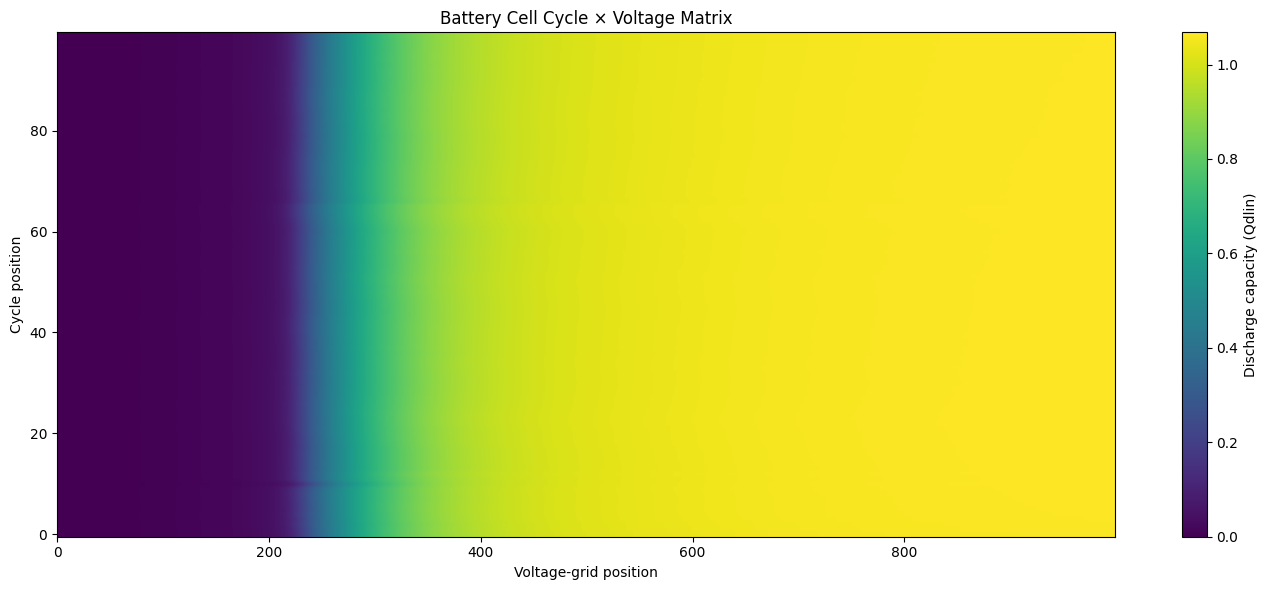

In [28]:
images = np.load(
    IMAGE_ROOT / "battery_images_100_train.npy"
)

plt.figure(figsize=(14, 6))

plt.imshow(
    images[0],
    aspect="auto",
    origin="lower",
    cmap="viridis"
)

plt.colorbar(
    label="Discharge capacity (Qdlin)"
)

plt.xlabel("Voltage-grid position")

plt.ylabel("Cycle position")

plt.title(
    "Battery Cell Cycle × Voltage Matrix"
)

plt.tight_layout()

plt.savefig(
    IMAGE_ROOT / "sample_battery_heatmap.png",
    dpi=300
)

plt.show()

In [29]:
def fit_medians(X):

    medians = np.nanmedian(
        X,
        axis=0
    )

    medians = np.where(
        np.isfinite(medians),
        medians,
        0.0
    )

    return medians


def apply_medians(X, medians):

    X = np.asarray(
        X,
        dtype=np.float32
    ).copy()

    invalid = ~np.isfinite(X)

    if invalid.any():

        rows, cols = np.where(invalid)

        X[rows, cols] = medians[cols]

    return X


PROCESSED = {}

PREPROCESSORS = {}

IMAGE_STATS = {}

for horizon in HORIZONS:

    print(f"\nPreprocessing {horizon}-cycle data")

    train = DATA[horizon]["train"]

    # --------------------------------
    # 1. Delta-Q preprocessing
    # --------------------------------

    delta_medians = fit_medians(
        train["delta"]
    )

    delta_train = apply_medians(
        train["delta"],
        delta_medians
    )

    delta_scaler = StandardScaler()

    delta_train = delta_scaler.fit_transform(
        delta_train
    )

    # --------------------------------
    # 2. Temporal summary preprocessing
    # --------------------------------

    n_cycles = horizon

    summary_train = train["summary"].reshape(
        -1,
        len(SUMMARY_FEATURES)
    )

    summary_medians = fit_medians(
        summary_train
    )

    summary_train = apply_medians(
        summary_train,
        summary_medians
    )

    summary_scaler = StandardScaler()

    summary_train = summary_scaler.fit_transform(
        summary_train
    )

    summary_train = summary_train.reshape(
        len(train["y"]),
        n_cycles,
        len(SUMMARY_FEATURES)
    )

    # --------------------------------
    # 3. 2-D image normalization
    # --------------------------------

    image_mean = float(
        np.mean(train["image"])
    )

    image_std = float(
        np.std(train["image"])
    )

    if image_std < 1e-8:
        image_std = 1.0

    IMAGE_STATS[horizon] = {
        "mean": image_mean,
        "std": image_std
    }

    # --------------------------------
    # Store fitted preprocessors
    # --------------------------------

    PREPROCESSORS[horizon] = {

        "delta_medians": delta_medians,

        "delta_scaler": delta_scaler,

        "summary_medians": summary_medians,

        "summary_scaler": summary_scaler,

        "image_mean": image_mean,

        "image_std": image_std

    }

    PROCESSED[horizon] = {}

    # --------------------------------
    # Transform all partitions
    # --------------------------------

    for split in SPLITS:

        data = DATA[horizon][split]

        if split == "train":

            delta = delta_train

            summary = summary_train

        else:

            delta = apply_medians(
                data["delta"],
                delta_medians
            )

            delta = delta_scaler.transform(
                delta
            )

            summary = data["summary"].reshape(
                -1,
                len(SUMMARY_FEATURES)
            )

            summary = apply_medians(
                summary,
                summary_medians
            )

            summary = summary_scaler.transform(
                summary
            )

            summary = summary.reshape(
                len(data["y"]),
                n_cycles,
                len(SUMMARY_FEATURES)
            )

        image = (
            data["image"] - image_mean
        ) / image_std

        image = image[:, None, :, :]

        PROCESSED[horizon][split] = {

            "delta": delta.astype(np.float32),

            "summary": summary.astype(np.float32),

            "image": image.astype(np.float32),

            "y": data["y"].copy(),

            "ids": data["ids"].copy()

        }

    print("Training-only normalization completed.")


Preprocessing 10-cycle data
Training-only normalization completed.

Preprocessing 30-cycle data
Training-only normalization completed.

Preprocessing 100-cycle data
Training-only normalization completed.


In [30]:
for horizon in HORIZONS:

    print(f"\nHorizon: {horizon}")

    for split in SPLITS:

        data = PROCESSED[horizon][split]

        print(
            split,
            "| Delta:", data["delta"].shape,
            "| Summary:", data["summary"].shape,
            "| Image:", data["image"].shape
        )

        assert np.isfinite(data["delta"]).all()

        assert np.isfinite(data["summary"]).all()

        assert np.isfinite(data["image"]).all()

print("\nAll normalized arrays are finite.")


Horizon: 10
train | Delta: (75, 1000) | Summary: (75, 10, 6) | Image: (75, 1, 10, 1000)
val | Delta: (24, 1000) | Summary: (24, 10, 6) | Image: (24, 1, 10, 1000)
test | Delta: (29, 1000) | Summary: (29, 10, 6) | Image: (29, 1, 10, 1000)

Horizon: 30
train | Delta: (75, 1000) | Summary: (75, 30, 6) | Image: (75, 1, 30, 1000)
val | Delta: (24, 1000) | Summary: (24, 30, 6) | Image: (24, 1, 30, 1000)
test | Delta: (29, 1000) | Summary: (29, 30, 6) | Image: (29, 1, 30, 1000)

Horizon: 100
train | Delta: (75, 1000) | Summary: (75, 100, 6) | Image: (75, 1, 100, 1000)
val | Delta: (24, 1000) | Summary: (24, 100, 6) | Image: (24, 1, 100, 1000)
test | Delta: (29, 1000) | Summary: (29, 100, 6) | Image: (29, 1, 100, 1000)

All normalized arrays are finite.


In [31]:
joblib.dump(
    PREPROCESSORS,
    PROCESSED_ROOT / "preprocessors.pkl"
)

np.savez_compressed(
    PROCESSED_ROOT / "image_normalization.npz",

    means=np.array([
        IMAGE_STATS[h]["mean"]
        for h in HORIZONS
    ]),

    stds=np.array([
        IMAGE_STATS[h]["std"]
        for h in HORIZONS
    ])
)

print("Preprocessing objects saved.")

Preprocessing objects saved.


In [32]:
train_targets = targets.loc[
    targets["part"] == "train",
    "cycle_life_target"
].to_numpy(dtype=float)

training_mean = np.mean(train_targets)

print("Number of training cells:", len(train_targets))

print("Training mean cycle life:", training_mean)

print("Expected reference: approximately 824.6")

assert len(train_targets) == 75

assert np.isfinite(train_targets).all()

# All horizons must use the same physical-cell targets
for horizon in HORIZONS:

    np.testing.assert_allclose(
        DATA[horizon]["train"]["y"],
        DATA[100]["train"]["y"]
    )

print("Training target verification completed.")

Number of training cells: 75
Training mean cycle life: 824.6
Expected reference: approximately 824.6
Training target verification completed.


In [33]:
summary_rows = []

for horizon in HORIZONS:

    for split in SPLITS:

        data = PROCESSED[horizon][split]

        summary_rows.append({

            "Horizon": horizon,

            "Partition": split,

            "Cells": len(data["y"]),

            "Delta_Features": data["delta"].shape[1],

            "Temporal_Cycles": data["summary"].shape[1],

            "Temporal_Features": data["summary"].shape[2],

            "Image_Height": data["image"].shape[2],

            "Image_Width": data["image"].shape[3],

            "Mean_Cycle_Life": np.mean(data["y"])

        })


preprocessing_summary = pd.DataFrame(summary_rows)

display(preprocessing_summary)

preprocessing_summary.to_csv(
    PROCESSED_ROOT / "preprocessing_summary.csv",
    index=False
)

print("\nPREPROCESSING COMPLETED")
print("Processed data:", PROCESSED_ROOT)
print("2D images:", IMAGE_ROOT)

,Horizon,Partition,Cells,Delta_Features,Temporal_Cycles,Temporal_Features,Image_Height,Image_Width,Mean_Cycle_Life
0,10,train,75,1000,10,6,10,1000,824.599976
1,10,val,24,1000,10,6,10,1000,859.916687
2,10,test,29,1000,10,6,10,1000,767.758606
3,30,train,75,1000,30,6,30,1000,824.599976
4,30,val,24,1000,30,6,30,1000,859.916687
5,30,test,29,1000,30,6,30,1000,767.758606
6,100,train,75,1000,100,6,100,1000,824.599976
7,100,val,24,1000,100,6,100,1000,859.916687
8,100,test,29,1000,100,6,100,1000,767.758606



PREPROCESSING COMPLETED
Processed data: C:\Users\lokan\Document\DL\ENDSEM\data\processed
2D images: C:\Users\lokan\Document\DL\ENDSEM\images_2d


In [34]:
# Save all normalized datasets

for horizon in HORIZONS:
    for split in SPLITS:

        data = PROCESSED[horizon][split]

        output_path = (
            PROCESSED_ROOT /
            f"normalized_{horizon}_{split}.npz"
        )

        np.savez_compressed(
            output_path,
            delta=data["delta"].astype(np.float32),
            summary=data["summary"].astype(np.float32),
            image=data["image"].astype(np.float32),
            y=data["y"].astype(np.float32),
            ids=data["ids"].astype(str)
        )

        print("Saved:", output_path)

print("All nine normalized datasets saved.")

Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_10_train.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_10_val.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_10_test.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_30_train.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_30_val.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_30_test.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_100_train.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_100_val.npz
Saved: C:\Users\lokan\Document\DL\ENDSEM\data\processed\normalized_100_test.npz
All nine normalized datasets saved.
